# Setup

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().resolve().parent))

import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split

from training.models import get_model_for_model_identification

# Generate Synthetic dataset

Generate data from an RLF model and an WM model described in the paper.

## Generate task sequences

In [4]:
from simulation.sequence_generator import create_stim_sequence

# Experimental task strcture.
pval = 1
num_blocks = 12
num_stim = 6
min_switches = [1200, 1200]
iter_per_stimuli = 13
num_actions = 3

all_seq = []
stim_iter_per_block = iter_per_stimuli - 1
for _ in range(10):
    one_seq = []
    i = 0
    while i < num_blocks:
        bseq = create_stim_sequence(stim_iter_per_block, num_stim)
        unique_values, counts = np.unique(bseq, return_counts=True)
        wrong_seq = not np.all(counts == (stim_iter_per_block + 1))
        if wrong_seq:
            continue

        i += 1
        one_seq.append(bseq)

    all_seq.append(one_seq)

## Simulate the RLF model performing on the task

In [9]:
from simulation.rlf import generate_rlf_parameters
from simulation.wm import generate_wm_parameters
from simulation.sim_agent import simulate_agent
from concurrent.futures import ProcessPoolExecutor
import tqdm


def _simulate_model(all_seq, parameters_dist, num_agents):
    with ProcessPoolExecutor(max_workers=2) as executor:
        futures = [
            executor.submit(
                simulate_agent,
                a,
                pval,
                num_blocks,
                [num_stim, num_stim],
                min_switches,
                iter_per_stimuli,
                num_actions,
                all_seq[a % len(all_seq)],
                params_dist=parameters_dist[a],
            )
            for a in range(num_agents)
        ]
        train_data_list = [future.result() for future in tqdm.tqdm(futures)]

    return pd.concat(train_data_list)


model_list = ["rlf", "wm"]
train_df = []
N_AGENTS = 100  # number of agents - change to your own needs

for model_name in model_list:
    parameters_dist = (
        generate_rlf_parameters(N_AGENTS)
        if model_name == "rlf"
        else generate_wm_parameters(N_AGENTS)
    )
    data = _simulate_model(all_seq, parameters_dist, N_AGENTS)
    data["model_type"] = model_name
    train_df.append(data)

train_df = pd.concat(train_df)
train_df.head(3)

100%|██████████| 100/100 [00:03<00:00, 25.97it/s]


,actions,stimuli,correct_actions,rewards,trials,isswitch,iscorrectaction,rpe_history,alpha,neg_alpha,...,beta,phi,stickiness,agentid,eps,delay_since_last_stimuli,block_no,condition,set_size,model_type
0,2,0,0,0,0,0,0,-0.333333,0.382206,0.382206,...,4.917021,0.039678,-0.654441,0,0.0,0,0,0,6,rlf
1,1,1,2,0,1,0,0,-0.333333,0.382206,0.382206,...,4.917021,0.039678,-0.654441,0,0.0,0,0,0,6,rlf
2,2,2,1,0,2,0,0,-0.333333,0.382206,0.382206,...,4.917021,0.039678,-0.654441,0,0.0,0,0,0,6,rlf


# Validate Synthetic dataset

/var/folders/6y/khb9drcn0p373bwf72szrzvm0000gn/T/ipykernel_32415/2590318168.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  res.groupby(["agentid", f"{key}_cat", "phi group"])[["rewards"]]
/var/folders/6y/khb9drcn0p373bwf72szrzvm0000gn/T/ipykernel_32415/2590318168.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  res.groupby(["agentid", f"{key}_cat", "phi group"])[["rewards"]]


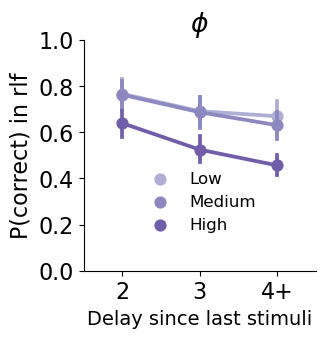

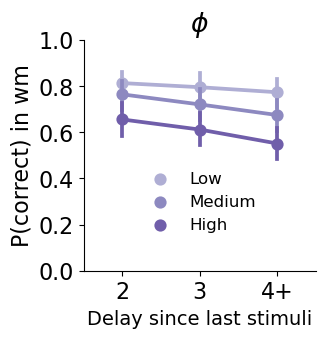

In [ ]:
key = "delay_since_last_stimuli"
for m, d in train_df.groupby("model_type"):
    res = d[d.delay_since_last_stimuli > 1].copy()
    # Create 5 equal-width bins for bias values
    res["phi group"] = pd.qcut(res["phi"], q=3, labels=["Low", "Medium", "High"])
    res[f"{key}_cat"] = res[key].apply(lambda x: "4+" if x > 4 else str(x))

    res = (
        res.groupby(["agentid", f"{key}_cat", "phi group"])[["rewards"]]
        .mean()
        .reset_index()
    )

    plt.rcParams.update({"font.size": 16})
    fig, ax = plt.subplots(1, 1, figsize=(3, 3), sharey=True)
    ax = sns.pointplot(
        data=res,
        x=f"{key}_cat",
        y="rewards",
        order=["2", "3", "4+"],
        hue="phi group",
        palette=sns.color_palette("Purples")[2:],
        ax=ax,
        ci=95,
    )
    ax.set_ylabel(f"P(correct) in {m}")
    ax.set_yticks(np.round(np.arange(0, 1.2, 0.2), 2))
    ax.set_title(r"$\phi$")
    ax.set_xlabel("Delay since last stimuli", fontsize=14)
    # sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), fontsize=12)
    sns.move_legend(
        ax,
        "lower center",
        bbox_to_anchor=(0.5, 0.1),
        ncol=1,
        fontsize=12,
        markerscale=1,
        frameon=False,
        title=None,
    )
    sns.despine()

# Extract input features and output labels

In [6]:
from utils.feature_utils import (
    get_iter_acc_with_switches,
    extract_features_blockless,
)
from typing import List, Optional, Tuple


def prepare_model_dataset(
    data: pd.DataFrame,
    feature_list: List[str],
    sorted_col: Optional[List[str]] = None,
    one_hot_encoding: Optional[List[str]] = None,
    sorting: bool = True,
    test_size: float = 0.1,
    random_state: int = 42,
    verbose: bool = True,
) -> Tuple[
    tf.Tensor,
    tf.Tensor,
    tf.Tensor,
    tf.Tensor,
    np.ndarray,
]:
    """Extracts features per model type, performs train/validation split, and

    returns concatenated TensorFlow tensors alongside one-hot encoded labels.
    """
    if sorted_col is None:
        sorted_col = ["agentid", "block_no", "stimuli"]
    if one_hot_encoding is None:
        one_hot_encoding = []

    model_types = data["model_type"].unique()
    num_classes = len(model_types)

    train_features, val_features = [], []
    train_labels, val_labels = [], []

    for idx, (model_name, group_data) in enumerate(
        data.groupby("model_type", sort=False)
    ):
        td_iter = get_iter_acc_with_switches(group_data)
        # Vectorized switch calculation (faster than .apply)
        td_iter["isswitch"] = (td_iter["trials"] == 0).astype(int)
        td_iter["delay_since_last_stimuli"] = group_data[
            "delay_since_last_stimuli"
        ].to_list()
        # Retain DataFrame index alignment to avoid index mismatch
        td_iter["prev_action"] = (
            group_data.groupby(["agentid", "block_no"])["actions"]
            .shift(1)
            .fillna(-1)
            .astype(int)
            .to_list()
        )

        td_iter_order = td_iter.sort_values(by=sorted_col) if sorting else td_iter

        features = extract_features_blockless(
            td_iter_order, feature_list, one_hot_encoding
        )
        labels = [idx] * len(features)

        trf, valf, train_l, val_l = train_test_split(
            features, labels, test_size=test_size, random_state=random_state
        )

        train_features.append(trf)
        val_features.append(valf)
        train_labels.extend(train_l)
        val_labels.extend(val_l)

        if verbose:
            print(f"Model: {model_name:<15} | Features shape: {features.shape}")

    # Convert to Tensors
    X_train = tf.concat(train_features, axis=0)
    X_val = tf.concat(val_features, axis=0)
    y_train = tf.keras.utils.to_categorical(train_labels, num_classes=num_classes)
    y_val = tf.keras.utils.to_categorical(val_labels, num_classes=num_classes)

    if verbose:
        print(f"\nFinal Train Shape: {X_train.shape} | Val Shape: {X_val.shape}")

    return X_train, X_val, y_train, y_val, model_types


feature_list = [
    "actions",
    "rewards",
    "stim_iter",
    "isswitch",
    "prev_action",
    "delay_since_last_stimuli",
]
(
    train_features,
    val_features,
    normalized_train_labels,
    normalized_val_labels,
    model_names,
) = prepare_model_dataset(
    data=train_df,
    feature_list=feature_list,
    sorted_col=["agentid", "block_no", "stimuli"],
    one_hot_encoding=[],
    sorting=True,
    test_size=0.1,
    random_state=42,
)

Model: rlf             | Features shape: (100, 936, 6)
Model: wm              | Features shape: (100, 936, 6)

Final Train Shape: (180, 936, 6) | Val Shape: (20, 936, 6)


## Shuffle dataset

In [7]:
from sklearn.utils import shuffle

train_features, normalized_train_labels = shuffle(
    train_features.numpy(), normalized_train_labels, random_state=0
)
val_features, normalized_val_labels = shuffle(
    val_features.numpy(), normalized_val_labels, random_state=0
)
print(train_features.shape, normalized_train_labels.shape)

(180, 936, 6) (180, 2)


# Train a neural estimator

In [16]:
### CHANGE ME
# this is a small network for demonstration purpose
# you can change the network architecture to your own needs
batch_size = 32
units = 32
dropout = 0.065
dropout1 = 0.1929
dropout2 = 0.113
learning_rate = 0.3
###

tf.keras.utils.set_random_seed(11)
identifier = (
    f"rlf_wm_B{batch_size}_U{units}_D{dropout}_D{dropout1}_D{dropout2}_{learning_rate}"
)
param_settings = {
    "feature_dim": train_features.shape[-1],
    "output_dims": normalized_train_labels.shape[-1],
    "units": units,
    "dropout": dropout,
    "dropout1": dropout1,
    "dropout2": dropout2,
    "learning_rate": learning_rate,
}
best_model = get_model_for_model_identification(param_settings)

print(identifier)

rlf_wm_B32_U32_D0.065_D0.1929_D0.113_0.3


In [17]:
callbacks = [EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)]

start = time.time()
history = best_model.fit(
    train_features,
    normalized_train_labels,
    epochs=10,  # CHANGE ME to higher number e.g., 600
    batch_size=batch_size,
    callbacks=callbacks,
    validation_data=(val_features, normalized_val_labels),
    verbose=2,
)

end = time.time()

Epoch 1/10


2026-11-01 13:51:27.500975: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


6/6 - 3s - 513ms/step - accuracy: 0.5444 - loss: 2.0211 - val_accuracy: 0.5000 - val_loss: 0.6977
Epoch 2/10
6/6 - 1s - 128ms/step - accuracy: 0.4667 - loss: 1.6198 - val_accuracy: 0.5500 - val_loss: 0.6938
Epoch 3/10
6/6 - 1s - 125ms/step - accuracy: 0.4611 - loss: 1.0912 - val_accuracy: 0.5000 - val_loss: 0.6964
Epoch 4/10
6/6 - 1s - 130ms/step - accuracy: 0.4611 - loss: 0.9428 - val_accuracy: 0.5000 - val_loss: 0.6968
Epoch 5/10
6/6 - 1s - 125ms/step - accuracy: 0.5056 - loss: 0.9612 - val_accuracy: 0.5000 - val_loss: 0.6947
Epoch 6/10
6/6 - 1s - 123ms/step - accuracy: 0.4889 - loss: 0.8695 - val_accuracy: 0.5000 - val_loss: 0.6933
Epoch 7/10
6/6 - 1s - 124ms/step - accuracy: 0.4944 - loss: 1.1164 - val_accuracy: 0.5000 - val_loss: 0.6932
Epoch 8/10
6/6 - 1s - 125ms/step - accuracy: 0.5000 - loss: 0.9356 - val_accuracy: 0.5000 - val_loss: 0.6942
Epoch 9/10
6/6 - 1s - 122ms/step - accuracy: 0.4889 - loss: 1.0501 - val_accuracy: 0.5000 - val_loss: 0.6950
Epoch 10/10
6/6 - 1s - 124ms/s

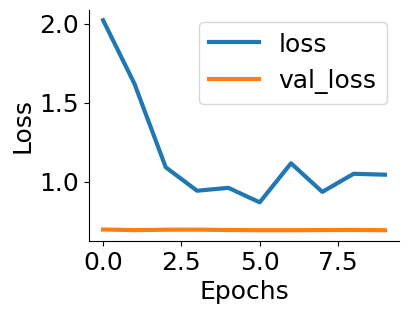

In [18]:
result = pd.DataFrame(history.history)

plt.rcParams.update({"font.size": 18})
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(4, 3))
ax.plot(result.index, result["loss"], linewidth=3, label="loss")
ax.plot(result.index, result["val_loss"], linewidth=3, label="val_loss")
ax.legend()
ax.set_xlabel("Epochs")
ax.set_ylabel("Loss")
sns.despine()

# Evaludate neural estimators

## Generate test dataset

In [10]:
N_TEST_AGENTS = 100  # number of agents - change to your own needs

test_df = []
for model_name in model_list:
    parameters_dist = (
        generate_rlf_parameters(N_TEST_AGENTS)
        if model_name == "rlf"
        else generate_wm_parameters(N_TEST_AGENTS)
    )
    data = _simulate_model(all_seq, parameters_dist, N_TEST_AGENTS)
    data["model_type"] = model_name
    test_df.append(data)

test_df = pd.concat(test_df)
test_df.head(3)

100%|██████████| 100/100 [00:03<00:00, 25.76it/s]


,actions,stimuli,correct_actions,rewards,trials,isswitch,iscorrectaction,rpe_history,alpha,neg_alpha,...,beta,phi,stickiness,agentid,eps,delay_since_last_stimuli,block_no,condition,set_size,model_type
0,2,0,1,0,0,0,0,-0.333333,0.484348,0.484348,...,13.056625,0.030655,0.728431,0,0.0,0,0,0,6,rlf
1,2,1,0,0,1,0,0,-0.333333,0.484348,0.484348,...,13.056625,0.030655,0.728431,0,0.0,0,0,0,6,rlf
2,2,2,2,1,2,0,1,0.666667,0.484348,0.484348,...,13.056625,0.030655,0.728431,0,0.0,0,0,0,6,rlf


## Extract test features

In [18]:
# @title extract test features

sorting = True
sorted_col = ["agentid", "block_no", "stimuli"]
all_test_features = []
all_test_labels = []
for idx, (model, data) in enumerate(test_df.groupby("model_type")):
    fd_iter = get_iter_acc_with_switches(data)
    fd_iter["delay_since_last_stimuli"] = data["delay_since_last_stimuli"].to_list()
    fd_iter["isswitch"] = fd_iter["trials"].apply(lambda x: 1 if x == 0 else 0)
    fd_iter["prev_action"] = (
        data.groupby(["agentid", "block_no"])["actions"]
        .shift(1)
        .fillna(-1)
        .astype(int)
        .to_list()
    )
    fd_iter_order = fd_iter.sort_values(by=sorted_col) if sorting else fd_iter
    features = extract_features_blockless(fd_iter_order, feature_list, [])
    all_test_features.append(features)
    all_test_labels.extend([idx] * len(features))
    print(model, features.shape)


all_test_features = tf.concat(all_test_features, 0)
all_test_labels_cat = tf.keras.utils.to_categorical(
    all_test_labels, num_classes=len(model_list)
)
print(all_test_features.shape, all_test_labels_cat.shape)

rlf (100, 936, 6)
wm (100, 936, 6)
(200, 936, 6) (200, 2)


## Inference

In [35]:
# LOAD trained model for RLF parameter estimation
model_name = "rlf_wm_27000a_B256_U96_D0.185_D0.0112_D0.01_0.0016_model.keras"
gru_model = tf.keras.models.load_model(f"./pretrained/{model_name}", compile=True)

In [19]:
accr = gru_model.evaluate(all_test_features, all_test_labels_cat)
print("Test set\n  Loss: {:0.3f}\n  Accuracy: {:0.3f}".format(accr[0], accr[1]))

2/7 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - acc: 0.9141 - loss: 0.2703

2026-11-02 11:17:59.816449: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - acc: 0.9350 - loss: 0.1760
Test set
  Loss: 0.176
  Accuracy: 0.935


1/7 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step

2026-11-02 11:47:52.649275: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step


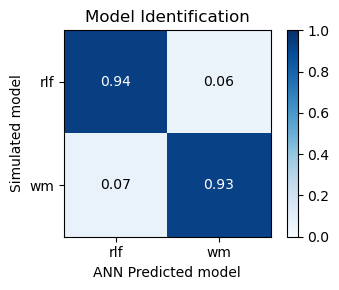

In [29]:
from sklearn.metrics import confusion_matrix

num_test_agents = len(test_df.agentid.unique())
all_prediction = gru_model.predict(all_test_features)

y_true, y_pred = all_test_labels, np.argmax(all_prediction, axis=1)
cf_matrix = confusion_matrix(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred) / num_test_agents

fig, ax = plt.subplots(figsize=(4, 3))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(model_list)))
ax.set_yticks(range(len(model_list)))
ax.set_xticklabels(model_list)
ax.set_yticklabels(model_list)

ax.set(
    xlabel="ANN Predicted model", ylabel="Simulated model", title="Model Identification"
)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        color = "white" if cm[i, j] > 0.5 else "black"
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color=color)

fig.colorbar(im, ax=ax)
fig.tight_layout()

## Permutation tests

In [31]:
from utils.feature_importance_utils import (
    permutation_importance_global_sequence,
)

ranking = permutation_importance_global_sequence(
    model=gru_model,
    X_val=all_test_features.numpy(),
    y_val=all_test_labels_cat,
    feature_names=feature_list,
    n_repeats=3,
    batch_size=64,
    shuffle_mode="sequence",
    block_size=32,
    random_state=123,
)

2026-11-02 11:53:06.998704: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Baseline loss: 0.17598102986812592
Permutation feature actions
Permutation loss: 2.0191221237182617
Permutation loss: 1.9139103889465332
Permutation loss: 1.9088400602340698
Permutation feature rewards
Permutation loss: 2.302344560623169
Permutation loss: 1.9978793859481812
Permutation loss: 2.0928542613983154
Permutation feature stim_iter
Permutation loss: 0.17598102986812592
Permutation loss: 0.17598102986812592
Permutation loss: 0.17598102986812592
Permutation feature isswitch
Permutation loss: 0.17598102986812592


2026-11-02 11:53:12.142362: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Permutation loss: 0.17598102986812592
Permutation loss: 0.17598102986812592
Permutation feature prev_action
Permutation loss: 2.271726608276367
Permutation loss: 2.3128247261047363
Permutation loss: 2.2710890769958496
Permutation feature delay_since_last_stimuli
Permutation loss: 0.7231957912445068
Permutation loss: 0.8838165998458862
Permutation loss: 0.6550712585449219


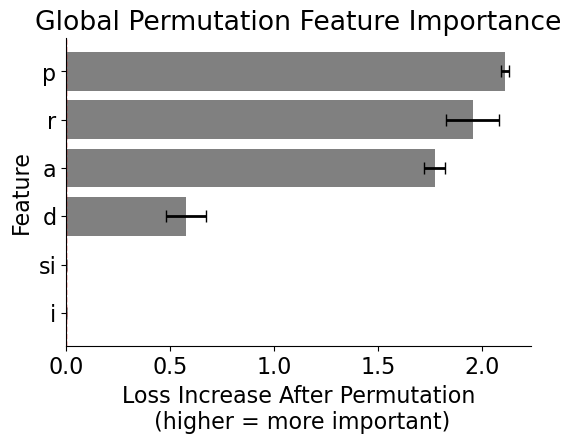

In [33]:
plt.rcParams.update({"font.size": 16})

fig, ax = plt.subplots(figsize=(6, 4))
ax = sns.barplot(
    data=ranking,
    x="importance_mean",
    y="feature",
    color="grey",
    ax=ax,
)
# add error bars if present
if "importance_std" in ranking.columns:
    ax.errorbar(
        x=ranking["importance_mean"],
        y=range(len(ranking)),
        xerr=ranking["importance_std"],
        fmt="none",
        ecolor="black",
        capsize=4,
        lw=2,
    )
ax.axvline(0, color="red", linestyle="--", linewidth=1)
ax.set_title(f"Global Permutation Feature Importance")  # ({k}% missing)")
ax.set_xlabel("Loss Increase After Permutation\n (higher = more important)")
short_labels = [
    "si" if l.get_text() == "stim_iter" else l.get_text()[:1]
    for l in ax.get_yticklabels()
]
ax.set_yticklabels(short_labels, rotation=0)
ax.set_ylabel("Feature")
sns.despine(ax=ax)